# Estrategia de Mean Reversion con Ornstein–Uhlenbeck y Deep Learning

**Datos:** `yfinance` · **Modelo:** proceso OU + red neuronal (PyTorch) · **Objetivo:** explotar la *estacionariedad local* del mercado y medir el **decaimiento de la vida media** de las anomalías.

## Índice
1. Marco teórico: mercado como sistema complejo y estacionariedad
2. Descarga de datos
3. Series estacionarias vs. no estacionarias (ADF / KPSS)
4. Retornos logarítmicos
5. Proceso de Ornstein–Uhlenbeck: estimación de θ, μ, σ y vida media
6. Estacionariedad local (ventanas móviles)
7. Ingeniería de variables
8. Red neuronal (walk-forward temporal)
9. Estrategia y backtest
10. Decaimiento de la vida media de la anomalía (event study)
11. Conclusiones y limitaciones

## 1. Marco teórico

**El mercado como sistema complejo.** Un mercado está formado por millones de agentes independientes que interactúan en paralelo sin un control central. Aun así, está sometido a *externalidades*: tendencias de especulación, noticias, resultados de la empresa (si el activo tiene una contraparte física), política monetaria, etc. Por eso **no es un sistema constante sino dinámico**: sus propiedades estadísticas cambian en el tiempo.

**Estacionariedad.** Un modelo estadístico necesita que la serie tenga *media y varianza constantes* (estacionariedad débil). Los precios no la cumplen (suelen comportarse como una caminata aleatoria con raíz unitaria), pero los **retornos logarítmicos**

$$r_t = \ln P_t - \ln P_{t-1}$$

suelen ser aproximadamente estacionarios. Así transformamos un activo no estacionario en uno con media y varianza (aprox.) constantes.

**Proceso de Ornstein–Uhlenbeck (1930).** Es una ecuación diferencial estocástica con *fuerza restauradora*:

$$dX_t = \theta(\mu - X_t)\,dt + \sigma\,dW_t$$

- $\mu$: centro de gravedad (media de largo plazo)
- $\theta>0$: velocidad de reversión (cuanto más lejos de $\mu$, más fuerte la fuerza que tira hacia él)
- $\sigma$: volatilidad del ruido

**Vida media de la anomalía.** El tiempo esperado para que la desviación se reduzca a la mitad:

$$t_{1/2} = \frac{\ln 2}{\theta}$$

Indica **cuánto tiempo podemos mantener una posición** antes de perder la ventaja.

**Hipótesis de trabajo.** El mercado no es estacionario globalmente, pero sí **localmente estacionario** en ciertos periodos. Usamos ventanas móviles para detectar esos regímenes, estimar el OU y alimentar una red neuronal que decide si la reversión es probable.

In [1]:
# !pip install -r requirements.txt
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from statsmodels.tsa.stattools import adfuller, kpss
from scipy.optimize import curve_fit
import torch, torch.nn as nn

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})
np.random.seed(42); torch.manual_seed(42)

# ----- PARÁMETROS (modifícalos) -----
TICKER   = "SPY"          # prueba también: KO, PEP, EWZ, GLD, XLP...
START    = "2010-01-01"
END      = None
LOOKBACK = 60             # ventana del "centro de gravedad" (media móvil del log-precio)
OU_WIN   = 252            # ventana para estimar OU localmente
HORIZON  = 5              # días hacia adelante que predice la red
ENTRY_Z, EXIT_Z = 1.5, 0.25
COST     = 0.0005         # costo por cambio de posición (5 bps)
DT       = 1.0            # 1 paso = 1 día de trading

## 2. Descarga de datos

(4239,) 2010-01-04 -> 2026-11-09


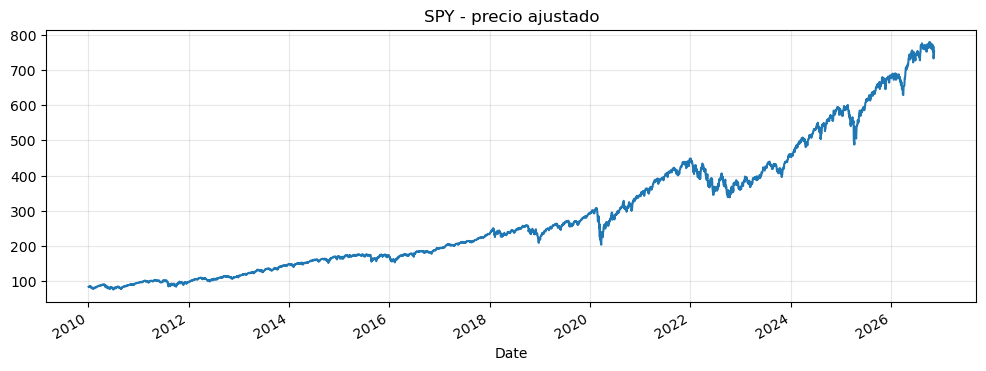

In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Descarga de datos con validación de seguridad
raw = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)

if raw.empty:
    print(f"Error: No se pudieron descargar datos para {TICKER}. Revisa tu conexión o actualiza yfinance.")
else:
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    
    px = raw["Close"].dropna().rename("price")
    
    if len(px) > 0:
        print(px.shape, px.index[0].date(), "->", px.index[-1].date())
        px.plot(title=f"{TICKER} - precio ajustado")
        plt.show()
    else:
        print("La columna 'Close' está vacía para este ticker.")

> ** Lectura de resultados — datos**
> Se descargaron **4 239 observaciones diarias (2010-01-04 → 2026-11-09, ≈ 16.8 años)**. La muestra cubre regímenes muy distintos (2011, 2015-16, Q4-2018, COVID-2020, 2022 y el castigo de abril-2025), lo cual es bueno para probar robustez. El precio de SPY muestra una **tendencia alcista muy marcada**: esa deriva es el principal enemigo de cualquier estrategia que asuma un "centro de gravedad" fijo, y reaparecerá en varios resultados de abajo.

## 3. Series estacionarias vs. no estacionarias

Usamos dos pruebas complementarias:
- **ADF**: $H_0$ = hay raíz unitaria (no estacionaria). p < 0.05 → rechazamos → estacionaria.
- **KPSS**: $H_0$ = es estacionaria. p < 0.05 → rechazamos → no estacionaria.

Concluimos estacionariedad con confianza cuando **ADF rechaza y KPSS no rechaza**.

In [3]:
def stationarity_report(s, name):
    s = s.dropna()
    adf_p  = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    verdict = "ESTACIONARIA" if (adf_p < .05 and kpss_p >= .05) else "NO estacionaria / ambigua"
    return pd.Series({"ADF p-value": adf_p, "KPSS p-value": kpss_p, "veredicto": verdict}, name=name)

logp = np.log(px).rename("logp")
ret  = logp.diff().rename("ret")          # retornos logarítmicos
pd.DataFrame([stationarity_report(px, "Precio"),
              stationarity_report(logp, "Log-precio"),
              stationarity_report(ret, "Retorno log")])

/tmp/ipykernel_8570/1224566090.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]
/tmp/ipykernel_8570/1224566090.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]
/tmp/ipykernel_8570/1224566090.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


,ADF p-value,KPSS p-value,veredicto
Precio,9.987580e-01,0.01,NO estacionaria / ambigua
Log-precio,9.350295e-01,0.01,NO estacionaria / ambigua
Retorno log,2.957570e-26,0.10,ESTACIONARIA


> ** Lectura de resultados — estacionariedad**
>
> | Serie | ADF p | KPSS p | Veredicto |
> |---|---|---|---|
> | Precio | 0.9988 | 0.01 | no estacionaria |
> | Log-precio | 0.935 | 0.01 | no estacionaria |
> | Retorno log | 3·10⁻²⁶ | 0.10 | **estacionaria** |
>
> Ambas pruebas coinciden: en **precio y log-precio** no se rechaza la raíz unitaria (ADF) y sí se rechaza la estacionariedad (KPSS); en **retornos** ocurre lo contrario. Es exactamente lo que predice la teoría y justifica trabajar con $r_t=\ln P_t-\ln P_{t-1}$.
> Detalle técnico: KPSS tabula p-values solo entre 0.01 y 0.10, así que "0.01" significa *p ≤ 0.01* y "0.10" significa *p ≥ 0.10*.
> **Matiz importante:** estacionario en media **no** significa tradable. Un retorno estacionario es justo lo que implica una caminata aleatoria en el precio; la estacionariedad de $r_t$ no prueba que exista reversión a la media en el nivel del precio.

## 4. Retornos logarítmicos: media y varianza (casi) constantes

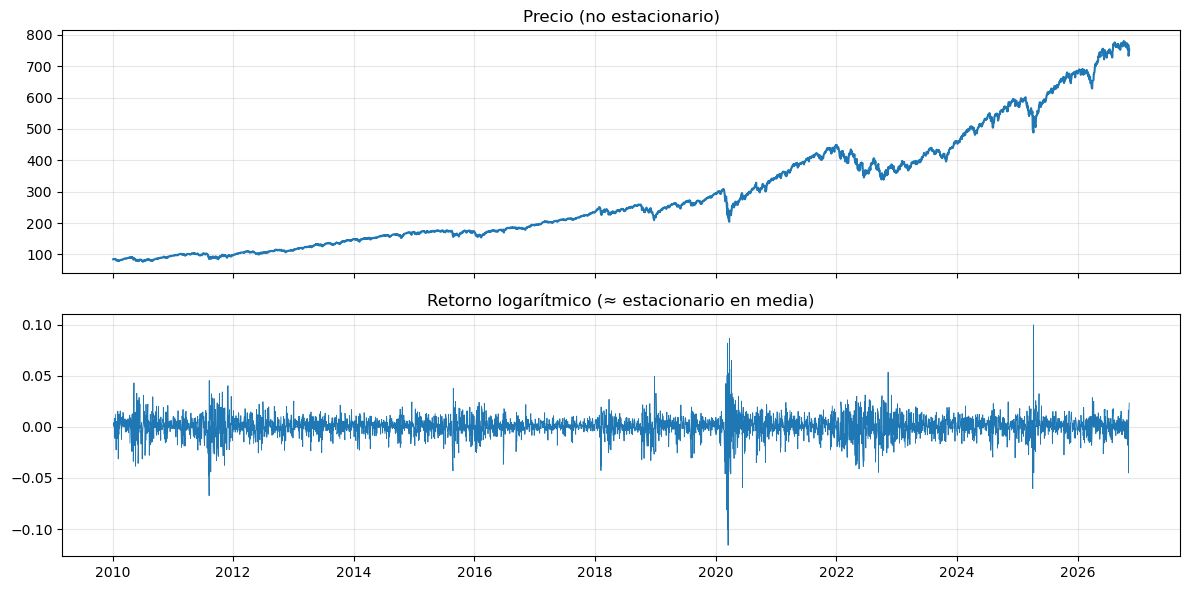

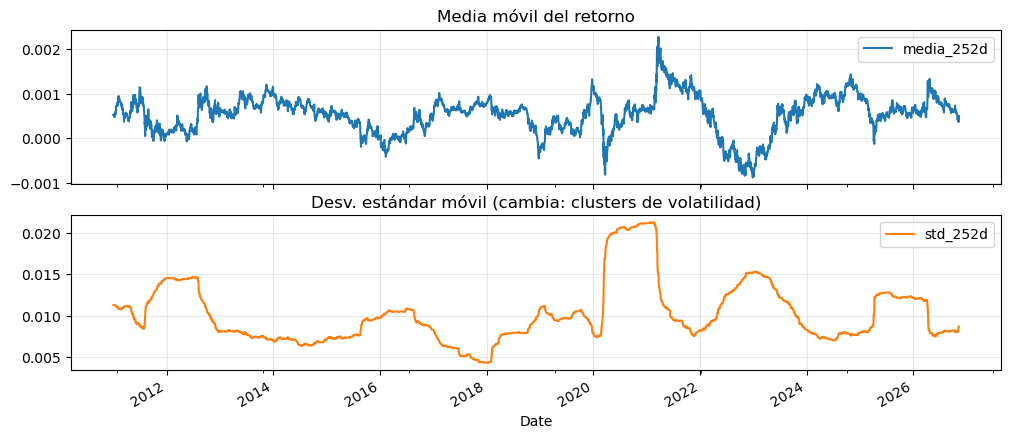

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(px); ax[0].set_title("Precio (no estacionario)")
ax[1].plot(ret, lw=.6); ax[1].set_title("Retorno logarítmico (≈ estacionario en media)")
plt.tight_layout(); plt.show()

roll = pd.DataFrame({"media_252d": ret.rolling(252).mean(), "std_252d": ret.rolling(252).std()})
roll.plot(subplots=True, figsize=(12, 5), title=["Media móvil del retorno", "Desv. estándar móvil (cambia: clusters de volatilidad)"]);

> ** Lectura de resultados — retornos y varianza**
> La media móvil del retorno oscila cerca de cero, pero la **desviación estándar móvil no es constante**: se dispara en los episodios de estrés (marzo-2020 es el más extremo; también 2022 y abril-2025) y decae en los periodos tranquilos. Es el fenómeno de *clusters de volatilidad* (heterocedasticidad condicional). Conclusión práctica: el retorno es estacionario **en media pero no en varianza**, por lo que cualquier umbral fijo en unidades de precio sería inestable; por eso el modelo trabaja con **z-scores** (desviación normalizada por su propia volatilidad móvil).

> La media es ~constante pero la **varianza no** (clusters de volatilidad). Esto confirma que el mercado es dinámico y que solo podemos asumir estacionariedad *local*.

## 5. Proceso de Ornstein–Uhlenbeck

Definimos la **desviación** respecto al centro de gravedad:

$$X_t = \ln P_t - \text{MA}_{L}(\ln P)_t$$

La discretización exacta del OU es un AR(1):

$$X_{t+1} = a + b\,X_t + \varepsilon_t,\qquad b=e^{-\theta\Delta t},\quad \mu=\frac{a}{1-b},\quad \sigma_\varepsilon^2=\sigma^2\frac{1-b^2}{2\theta}$$

Despejando: $\theta = -\ln(b)/\Delta t$ y $t_{1/2}=\ln 2/\theta$. Solo hay reversión si $0<b<1$.

In [5]:
def fit_ou(x, dt=DT):
    x = np.asarray(x); x0, x1 = x[:-1], x[1:]
    b, a = np.polyfit(x0, x1, 1)
    if not (0 < b < 1):
        return dict(theta=np.nan, mu=np.nan, sigma=np.nan, half_life=np.inf, b=b)
    theta = -np.log(b)/dt
    mu    = a/(1-b)
    resid = x1 - (a + b*x0)
    sigma = resid.std(ddof=2)*np.sqrt(2*theta/(1-b**2))
    return dict(theta=theta, mu=mu, sigma=sigma, half_life=np.log(2)/theta, b=b)

dev = (logp - logp.rolling(LOOKBACK).mean()).rename("dev")
print("OU global sobre la desviación:", {k: round(v, 4) for k, v in fit_ou(dev.dropna()).items()})

OU global sobre la desviación: {'theta': 0.0401, 'mu': 0.0152, 'sigma': 0.0108, 'half_life': 17.2906, 'b': 0.9607}


> ** Lectura de resultados — OU global**
>
> | Parámetro | Valor | Interpretación |
> |---|---|---|
> | $b$ | 0.9607 | autocorrelación a 1 día de la desviación |
> | $\theta$ | 0.0401 / día | velocidad de reversión |
> | **Vida media** | **17.3 días** | tiempo para que la desviación se reduzca a la mitad |
> | $\mu$ | **+0.0152** | la desviación media es **+1.5 %**, no 0 |
> | $\sigma$ | 0.0108 | ruido diario; desv. estándar estacionaria $\sigma/\sqrt{2\theta}\approx 3.8\,\%$ |
>
> Dos advertencias que cambian la interpretación:
> 1. **$\mu\neq 0$ es la deriva alcista disfrazada.** El precio de SPY está, en promedio, 1.5 % *por encima* de su media de 60 días, simplemente porque sube. Nuestro z-score no se resta esa media, así que las señales "vendido por sobrecompra" (z > 1.5) pelean contra la tendencia. Esto anticipa el mal resultado del lado corto.
> 2. **Parte de la reversión es mecánica.** La desviación se mide contra una media móvil de 60 días; esa media persigue al precio, lo que *fabrica* autocorrelación aunque el precio sea una caminata aleatoria pura. En una simulación mía (Gaussiana, volatilidad parecida a SPY, 300 trayectorias) una caminata aleatoria da $b\approx 0.974$ y vida media ≈ **27 días** (rango 5–95 %: 22–32). El $b=0.9607$ y los 17.3 días de SPY quedan *por debajo* de ese rango, lo que sugiere que sí hay algo de reversión genuina, pero modesta. La siguiente celda lo contrasta formalmente con los **propios** retornos de SPY barajados.

SPY real : b = 0.9607 | vida media = 17.3 d
Barajado : b = 0.9742 (5-95%: 0.9694 - 0.9784) | vida media mediana = 26.5 d
Percentil de SPY dentro del placebo: 0.0%  (cerca de 0% = más reversión de la que da el azar)


,VR real,VR azar p5,VR azar p95,señal
2,0.899,0.978,1.026,reversión significativa
5,0.864,0.941,1.052,reversión significativa
10,0.799,0.911,1.105,reversión significativa
20,0.770,0.859,1.115,reversión significativa
60,0.582,0.778,1.224,reversión significativa


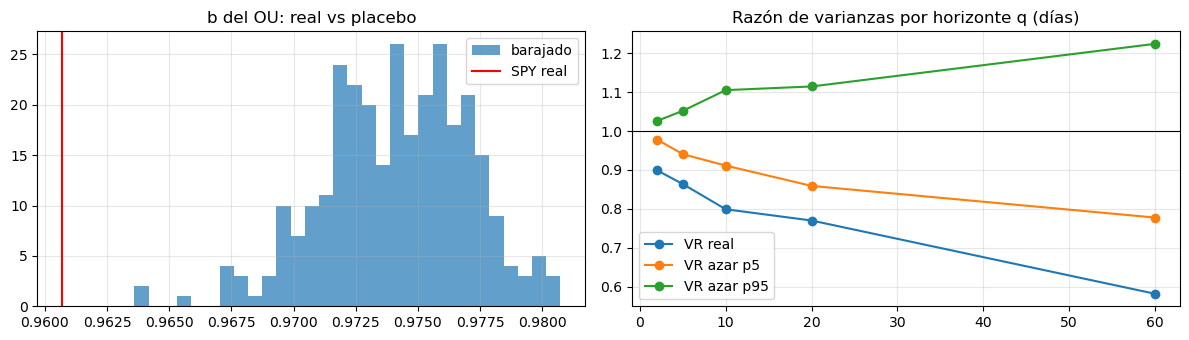

In [6]:
# ¿La reversión es real o un artefacto de usar una media móvil? -> PLACEBO
# Barajamos los retornos de SPY (misma distribución y deriva, sin dependencia serial) y repetimos el OU.
real = fit_ou(dev.dropna())
rng = np.random.default_rng(1); r_arr = ret.dropna().values
sims = []
for _ in range(300):
    lp_s = pd.Series(np.cumsum(rng.permutation(r_arr)))
    o = fit_ou((lp_s - lp_s.rolling(LOOKBACK).mean()).dropna())
    sims.append((o["b"], o["half_life"]))
sims = pd.DataFrame(sims, columns=["b", "half_life"])
pct = (sims["b"] <= real["b"]).mean()
print(f"SPY real : b = {real['b']:.4f} | vida media = {real['half_life']:.1f} d")
print(f"Barajado : b = {sims['b'].median():.4f} (5-95%: {sims['b'].quantile(.05):.4f} - {sims['b'].quantile(.95):.4f}) | vida media mediana = {sims['half_life'].median():.1f} d")
print(f"Percentil de SPY dentro del placebo: {pct:.1%}  (cerca de 0% = más reversión de la que da el azar)")

# Razón de varianzas: VR(q) < 1 => reversión; VR(q) > 1 => momentum/tendencia
def variance_ratio(r, q):
    r = np.asarray(r); rq = pd.Series(r).rolling(q).sum().dropna().values
    return rq.var(ddof=1) / (q * r.var(ddof=1))
qs = (2, 5, 10, 20, 60)
vr_real = pd.Series({q: variance_ratio(r_arr, q) for q in qs})
vr_sim = pd.DataFrame({q: [variance_ratio(rng.permutation(r_arr), q) for _ in range(150)] for q in qs})
vr_tab = pd.DataFrame({"VR real": vr_real, "VR azar p5": vr_sim.quantile(.05), "VR azar p95": vr_sim.quantile(.95)})
vr_tab["señal"] = np.where(vr_tab["VR real"] < vr_tab["VR azar p5"], "reversión significativa",
                   np.where(vr_tab["VR real"] > vr_tab["VR azar p95"], "tendencia significativa", "indistinguible del azar"))
display(vr_tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(sims["b"], bins=30, alpha=.7, label="barajado"); ax[0].axvline(real["b"], c="r", label="SPY real"); ax[0].set_title("b del OU: real vs placebo"); ax[0].legend()
vr_tab[["VR real", "VR azar p5", "VR azar p95"]].plot(ax=ax[1], marker="o"); ax[1].axhline(1, c="k", lw=.8); ax[1].set_title("Razón de varianzas por horizonte q (días)")
plt.tight_layout(); plt.show()

> ** Cómo leer la celda anterior (regla de decisión)**
> - Si el **percentil de SPY ≈ 0–5 %**, la reversión excede lo que produce el azar con la media móvil: hay algo que explotar.
> - Si cae en el **centro** de la distribución, el "OU" es un artefacto del método y no hay estrategia.
> - En la razón de varianzas, **VR < p5** a horizontes de 5–20 días confirma reversión *en el precio* (no solo en la desviación). Un VR dentro de la banda azul se interpreta como indistinguible de una caminata aleatoria.
> Esta es la prueba **previa** a cualquier modelo: si no hay dependencia serial real, ninguna red neuronal la va a inventar.

## 6. Estacionariedad local y OU móvil
Estimamos $b$, $\theta$ y la vida media en ventanas móviles (vectorizado, sin look-ahead) y un ADF móvil para detectar regímenes localmente estacionarios.

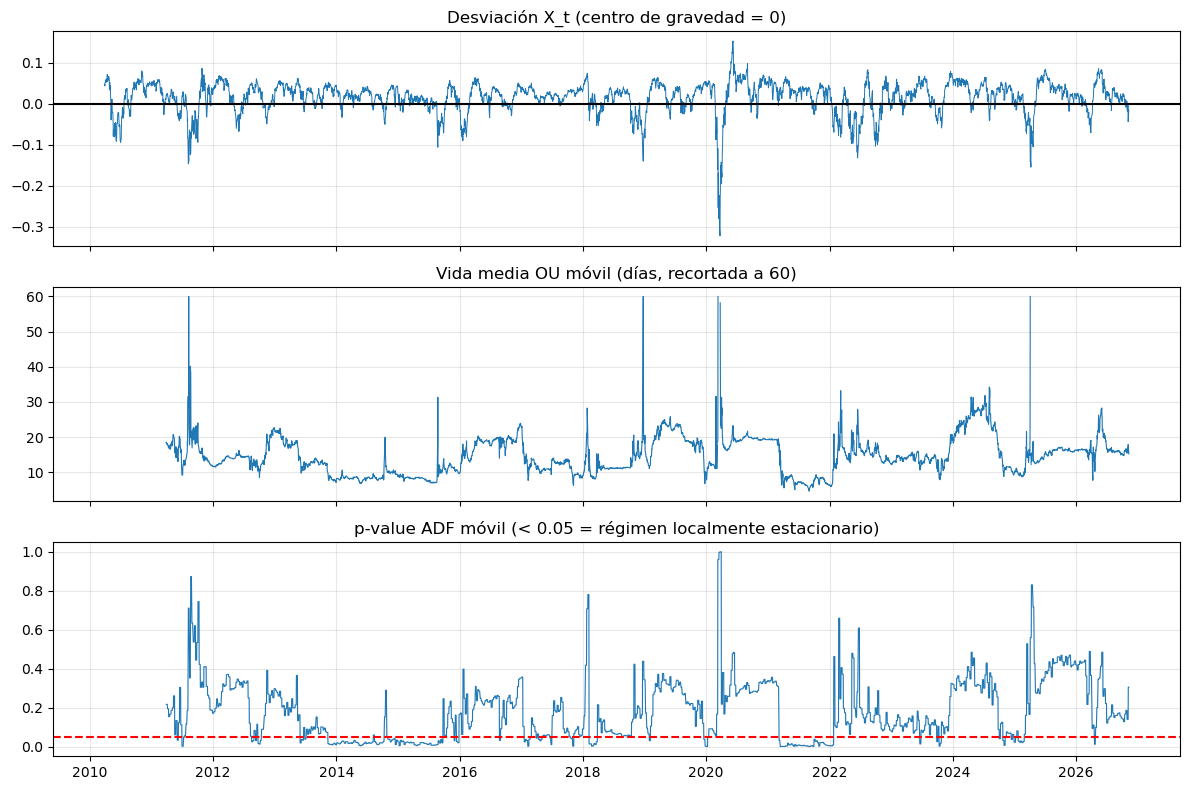

% del tiempo en régimen localmente estacionario (p<0.05): 23.1%


In [7]:
def rolling_ou(x, win=OU_WIN, dt=DT):
    x0, x1 = x.shift(1), x
    b = x0.rolling(win).cov(x1) / x0.rolling(win).var()
    theta = -np.log(b.where((b > 0) & (b < 1)))/dt
    hl = np.log(2)/theta
    return b.rename("b"), theta.rename("theta"), hl.rename("half_life")

b, theta, hl = rolling_ou(dev)

def rolling_adf_p(x, win=OU_WIN, step=5):
    out = pd.Series(np.nan, index=x.index)
    vals = x.values
    for i in range(win, len(x), step):
        seg = vals[i-win:i]
        if np.isnan(seg).any(): continue
        out.iloc[i] = adfuller(seg, maxlag=5, regression="c")[1]
    return out.ffill().rename("adf_p")

adf_p = rolling_adf_p(dev)

fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
ax[0].plot(dev, lw=.7); ax[0].axhline(0, c="k"); ax[0].set_title("Desviación X_t (centro de gravedad = 0)")
ax[1].plot(hl.clip(upper=60), lw=.8); ax[1].set_title("Vida media OU móvil (días, recortada a 60)")
ax[2].plot(adf_p, lw=.8); ax[2].axhline(.05, c="r", ls="--"); ax[2].set_title("p-value ADF móvil (< 0.05 = régimen localmente estacionario)")
plt.tight_layout(); plt.show()
print(f"% del tiempo en régimen localmente estacionario (p<0.05): {(adf_p<.05).mean():.1%}")

> ** Lectura de resultados — OU móvil y estacionariedad local**
> - **Desviación $X_t$:** casi siempre *positiva* (entre 0 y +0.08): es la deriva alcista. Las caídas son **asimétricas**: profundas, rápidas y raras (≈ −0.32 en marzo-2020, ≈ −0.15 en abril-2025, ≈ −0.14 en 2018 y 2022), mientras que los excesos al alza son superficiales y persistentes. Esa asimetría hace al lado **largo** (comprar caídas) mucho más razonable que el lado corto.
> - **Vida media móvil:** vive en el rango **≈ 8–25 días** (mediana ≈ 14 días), con mínimos de 5–8 días en 2014 y 2021-22 y **picos espurios** (> 40–60 días) justo en las crisis (2011, fin-2018, 2020, abril-2025): cuando más se necesita la estimación, es cuando el OU se rompe.
> - **ADF móvil:** solo el **23.1 %** del tiempo hay régimen localmente estacionario (p < 0.05). Los bloques "buenos" se concentran en **2014-2016, 2020-21 y partes de 2022**; en **2023-2026** el p-value rara vez baja de 0.1 y suele estar entre 0.2 y 0.5. Es decir: **el periodo de test fue, según este criterio, un régimen desfavorable para mean reversion**, mientras que el de entrenamiento (2011-2020) tuvo muchas más ventanas estacionarias. Hay un cambio de régimen entre train y test que el modelo no pudo anticipar.
> Esto valida la hipótesis de partida (el mercado es *localmente* estacionario, no globalmente) pero también su costo: el régimen favorable aparece menos de una cuarta parte del tiempo.

## 7. Ingeniería de variables

In [8]:
sig = dev.rolling(OU_WIN).std()
z = (dev / sig).rename("z")                       # z-score de la desviación

feat = pd.concat([
    z, z.diff(1).rename("dz1"), z.diff(5).rename("dz5"),
    ret.rename("r1"), ret.rolling(5).sum().rename("r5"),
    ret.rolling(20).std().rename("vol20"),
    np.log1p(hl.clip(upper=250)).rename("log_hl"),
    theta.fillna(0).rename("theta"),
    b.rename("b"), adf_p,
], axis=1)

fwd = (logp.shift(-HORIZON) - logp).rename("fwd")   # TARGET: retorno futuro a HORIZON días
data = pd.concat([feat, fwd], axis=1)
data_f = data.dropna(subset=feat.columns.tolist())  # filas con features completas
print(data_f.shape)
data_f.tail()

(3914, 11)


,z,dz1,dz5,r1,r5,vol20,log_hl,theta,b,adf_p,fwd
Date,,,,,,,,,,,
2026-11-03,-0.586560,0.123427,-0.696781,0.002987,-0.020092,0.007044,2.878507,0.041289,0.959552,0.139536,NaN
2026-11-04,0.010417,0.596977,-0.223203,0.016383,-0.007147,0.008105,2.812139,0.044303,0.956664,0.139536,NaN
2026-11-05,-1.583262,-1.593679,-1.676133,-0.045093,-0.048413,0.012825,2.939061,0.038727,0.962013,0.139536,NaN
2026-11-06,-1.426957,0.156306,-0.874873,0.003119,-0.027406,0.012739,2.920818,0.039481,0.961288,0.305103,NaN
2026-11-09,-0.573169,0.853788,0.136818,0.023389,0.000784,0.014027,2.785872,0.045560,0.955462,0.305103,NaN


## 8. Red neuronal con validación temporal (walk-forward)

Partimos la serie **cronológicamente** (60 % train / 20 % val / 20 % test). El escalado se ajusta *solo con train* para evitar fuga de información. La red aprende a predecir el retorno a `HORIZON` días a partir del estado del OU; así complementa la regla clásica de z-score filtrando cuándo la reversión es realmente probable.

train: 2011-04-04 2020-08-07 | val: 2020-08-10 | test: 2023-09-19 -> 2026-11-02
TEST -> IC (Spearman): 0.134 | acierto direccional: 61.3%


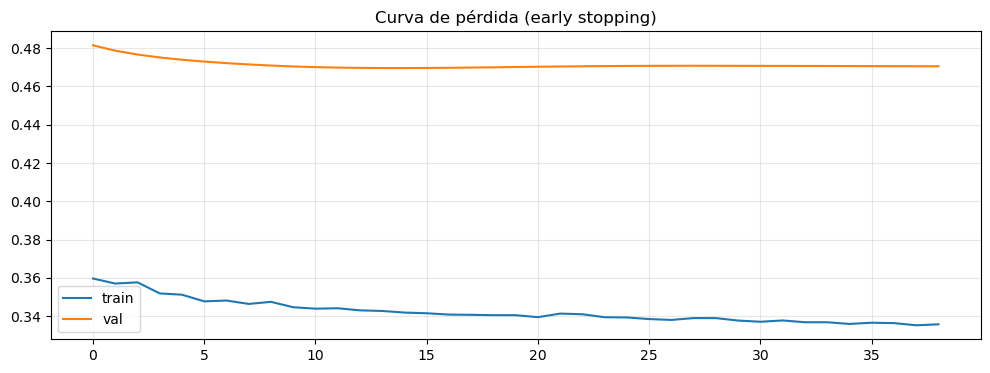

In [9]:
FEATS = feat.columns.tolist()
d = data_f.dropna(subset=["fwd"])                  # solo para entrenar/evaluar
n = len(d); i1, i2 = int(n*.6), int(n*.8)
tr, va, te = d.iloc[:i1], d.iloc[i1:i2], d.iloc[i2:]
print("train:", tr.index[0].date(), tr.index[-1].date(), "| val:", va.index[0].date(), "| test:", te.index[0].date(), "->", te.index[-1].date())

mu_f, sd_f = tr[FEATS].mean(), tr[FEATS].std().replace(0, 1)
y_sd = tr["fwd"].std()
def X_(df): return torch.tensor(((df[FEATS]-mu_f)/sd_f).values, dtype=torch.float32)
def y_(df): return torch.tensor((df["fwd"]/y_sd).values, dtype=torch.float32).unsqueeze(1)

class Net(nn.Module):
    def __init__(s, k):
        super().__init__()
        s.f = nn.Sequential(nn.Linear(k,64), nn.ReLU(), nn.Dropout(.2),
                            nn.Linear(64,32), nn.ReLU(), nn.Dropout(.2), nn.Linear(32,1))
    def forward(s, x): return s.f(x)

model = Net(len(FEATS)); opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=1e-3)
loss_fn = nn.HuberLoss()
Xtr, ytr, Xva, yva = X_(tr), y_(tr), X_(va), y_(va)
best, best_state, patience, bad = np.inf, None, 25, 0
hist = []
for ep in range(400):
    model.train(); opt.zero_grad(); l = loss_fn(model(Xtr), ytr); l.backward(); opt.step()
    model.eval()
    with torch.no_grad(): lv = loss_fn(model(Xva), yva).item()
    hist.append((l.item(), lv))
    if lv < best - 1e-5: best, bad, best_state = lv, 0, {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= patience: break
model.load_state_dict(best_state); model.eval()
pd.DataFrame(hist, columns=["train", "val"]).plot(title="Curva de pérdida (early stopping)");

with torch.no_grad(): pred = pd.Series(model(X_(data_f)).squeeze().numpy()*y_sd, index=data_f.index, name="pred")
ic = te["fwd"].corr(pred.reindex(te.index), method="spearman")
hit = (np.sign(te["fwd"]) == np.sign(pred.reindex(te.index))).mean()
print(f"TEST -> IC (Spearman): {ic:.3f} | acierto direccional: {hit:.1%}")

> **Lectura de resultados — red neuronal**
> Partición cronológica: train 2011-04 → 2020-08, val 2020-08 → 2023-09, **test 2023-09-19 → 2026-11-02**. En test: **IC de Spearman = 0.134** y **acierto direccional = 61.3 %**. A primera vista parece señal, pero hay tres razones para no confiarse (la celda siguiente las cuantifica):
> 1. **Tasa base:** en un mercado alcista, el retorno a 5 días es positivo ≈ 60 % de las veces. Un clasificador "siempre sube" ya acierta cerca del 61 %; el acierto de la red debe compararse contra esa tasa, no contra 50 %.
> 2. **Observaciones solapadas:** el objetivo es el retorno a 5 días y se muestrea todos los días, así que cada observación comparte 4/5 de su ventana con la siguiente. La muestra efectiva es ≈ n/5 y el IC parece más significativo de lo que es (con ~150 observaciones efectivas, el error estándar del IC es ≈ 0.08 y 0.134 queda en ≈ 1.7 errores estándar: **marginal**).
> 3. **Sesgo alcista:** si la red aprendió simplemente a predecir "sube" cuando la volatilidad es baja, replicaría la deriva y no la reversión.

In [10]:
# DIAGNÓSTICO DE LA RED: ¿tiene señal propia o solo aprendió la deriva alcista?
y_te, p_te = te["fwd"], pred.reindex(te.index)
base_up = (y_te > 0).mean()
print(f"Tasa base (días con retorno futuro > 0, test) : {base_up:.1%}   <- acierto de un clasificador 'siempre sube'")
print(f"Acierto direccional de la NN                   : {(np.sign(y_te) == np.sign(p_te)).mean():.1%}")
print(f"% de predicciones positivas                    : {(p_te > 0).mean():.1%}   (si ≈ 100% -> solo aprendió la deriva)")
print(f"Correlación pred vs z (test)                   : {p_te.corr(z.reindex(te.index)):.3f}   (negativa = usa la reversión)")

rows = []
for nm, df_ in [("train", tr), ("val", va), ("test", te)]:
    sub = df_.iloc[::HORIZON]                         # sin solapamiento
    ic_all = df_["fwd"].corr(pred.reindex(df_.index), method="spearman")
    ic_no = sub["fwd"].corr(pred.reindex(sub.index), method="spearman")
    t_ic = ic_no * np.sqrt((len(sub) - 2) / (1 - ic_no**2))
    rows.append(dict(muestra=nm, n=len(df_), n_efectivo=len(sub), IC_total=ic_all, IC_sin_solape=ic_no, t_stat=t_ic))
display(pd.DataFrame(rows).set_index("muestra").round(3))

# Rendimiento medio por quintil de predicción (debe ser monótono si hay señal)
q = pd.qcut(p_te, 5, labels=["Q1 (más bajista)", "Q2", "Q3", "Q4", "Q5 (más alcista)"])
display(y_te.groupby(q).agg(["mean", "count"]).rename(columns={"mean": "retorno futuro medio"}).round(4))

# ¿Funciona donde importa? (solo cuando |z| supera el umbral de entrada)
ext = te[z.reindex(te.index).abs() > ENTRY_Z]
print(f"\nSolo señales extremas (|z|>{ENTRY_Z}): n = {len(ext)} | IC = {ext['fwd'].corr(pred.reindex(ext.index), method='spearman'):.3f}")

Tasa base (días con retorno futuro > 0, test) : 61.3%   <- acierto de un clasificador 'siempre sube'
Acierto direccional de la NN                   : 61.3%
% de predicciones positivas                    : 100.0%   (si ≈ 100% -> solo aprendió la deriva)
Correlación pred vs z (test)                   : -0.055   (negativa = usa la reversión)


,n,n_efectivo,IC_total,IC_sin_solape,t_stat
muestra,,,,,
train,2345,469,0.103,0.095,2.070
val,782,157,0.075,0.112,1.398
test,782,157,0.134,0.138,1.733


,retorno futuro medio,count
pred,,
Q1 (más bajista),0.0025,157
Q2,-0.0002,156
Q3,0.0022,156
Q4,0.0053,156
Q5 (más alcista),0.0078,157



Solo señales extremas (|z|>1.5): n = 214 | IC = 0.112


> ** Cómo leer la celda anterior**
> - **Edge real de la red** ⇒ acierto *claramente por encima* de la tasa base, IC sin solape con |t| > 2, retornos **monótonos** por quintil y IC estable entre train, val y test.
> - Si el IC de **train ≫ test**, hubo sobreajuste/cambio de régimen (lo esperable dado el cambio de ADF visto arriba).
> - Si casi todas las predicciones son positivas, la red es un filtro de "mercado alcista", no de reversión.

## 9. Estrategia y backtest

**Reglas**
- **Entrada larga:** $z < -z_{entry}$ y (modelo) predicción > 0. **Corta:** $z > z_{entry}$ y predicción < 0.
- **Salida:** $|z|$ vuelve a $z_{exit}$, o **stop temporal = 2 × vida media OU** al entrar (si la anomalía no revirtió en ese tiempo, la ventaja se agotó).
- La posición se aplica con *1 día de rezago* (sin look-ahead) y se descuentan costos.

                          Retorno anual  Vol anual  Sharpe  Max DD  \
Mean Reversion + NN               0.031      0.094   0.334  -0.131   
Mean Reversion (z-score)         -0.046      0.118  -0.389  -0.221   
Buy & Hold SPY                    0.187      0.151   1.241  -0.173   

                          % días en mercado  
Mean Reversion + NN                   0.075  
Mean Reversion (z-score)              0.453  
Buy & Hold SPY                        1.000  


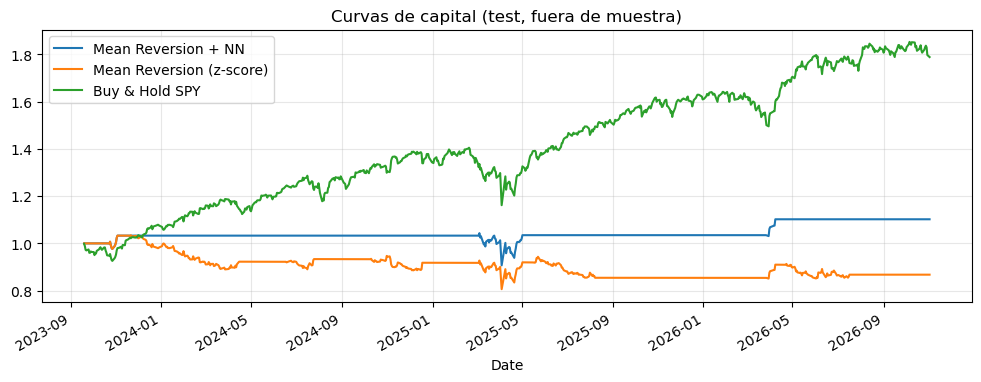

In [11]:
def build_positions(z, pred, hl, entry=ENTRY_Z, exit_=EXIT_Z, use_model=True, hold_mult=2.0, allow_short=True):
    zv, pv, hv = z.values, pred.values, hl.values
    pos = np.zeros(len(zv)); cur, held, max_hold = 0, 0, np.inf
    for t in range(len(zv)):
        if np.isnan(zv[t]): pos[t] = 0; cur = 0; continue
        if cur != 0:
            held += 1
            done = (cur == 1 and zv[t] >= -exit_) or (cur == -1 and zv[t] <= exit_) or held > max_hold
            if done: cur = 0
        if cur == 0:
            ok_l = zv[t] < -entry and (not use_model or (not np.isnan(pv[t]) and pv[t] > 0))
            ok_s = allow_short and zv[t] > entry and (not use_model or (not np.isnan(pv[t]) and pv[t] < 0))
            if ok_l or ok_s:
                cur = 1 if ok_l else -1; held = 0
                h = hv[t]; max_hold = hold_mult*h if np.isfinite(h) and h > 0 else 20
        pos[t] = cur
    return pd.Series(pos, index=z.index)

def run_bt(pos, ret, cost=COST):
    p = pos.shift(1).fillna(0)
    return (p*ret - cost*pos.diff().abs().fillna(0)).dropna()

def metrics(r, name):
    eq = r.cumsum().apply(np.exp); dd = (eq/eq.cummax()-1).min()
    return pd.Series({"Retorno anual": r.mean()*252, "Vol anual": r.std()*np.sqrt(252),
                      "Sharpe": r.mean()/r.std()*np.sqrt(252) if r.std() > 0 else np.nan,
                      "Max DD": dd, "% días en mercado": (r != 0).mean()}, name=name)

idx = te.index
pred_full = pred.reindex(data_f.index)
pos_model = build_positions(z.reindex(idx), pred_full.reindex(idx), hl.reindex(idx), use_model=True)
pos_plain = build_positions(z.reindex(idx), pred_full.reindex(idx), hl.reindex(idx), use_model=False)
r_ret = ret.reindex(idx)

res = {"Mean Reversion + NN": run_bt(pos_model, r_ret),
       "Mean Reversion (z-score)": run_bt(pos_plain, r_ret),
       f"Buy & Hold {TICKER}": r_ret.dropna()}
print(pd.DataFrame([metrics(v, k) for k, v in res.items()]).round(3))
pd.DataFrame({k: v.cumsum().apply(np.exp) for k, v in res.items()}).plot(title="Curvas de capital (test, fuera de muestra)");

> **Lectura de resultados — backtest (test fuera de muestra, 2023-09 → 2026-11, ≈ 3.1 años)**
>
> | Estrategia | Ret. anual | Vol | Sharpe | Max DD | % días en mercado |
> |---|---|---|---|---|---|
> | MR + NN | 3.1 % | 9.4 % | **0.33** | −13.1 % | **7.5 %** (≈ 59 días) |
> | MR (z-score puro) | −4.6 % | 11.8 % | **−0.39** | −22.1 % | 45.3 % |
> | Buy & Hold SPY | 18.7 % | 15.1 % | **1.24** | −17.3 % | 100 % |
>
> 1. **La mean reversion pura pierde dinero** (Sharpe negativo y el peor drawdown de los tres). Opera casi la mitad del tiempo contra la tendencia, sobre todo en el lado corto, tal como anticipaban $\mu=+1.5\%$ y la asimetría de $X_t$.
> 2. **La red mejora mucho el resultado, pero sobre todo porque *opera menos*:** pasa de 45 % a 7.5 % de exposición. Su valor principal es de **filtro** (evitar malas señales), no de generación de alfa.
> 3. **La curva de capital está dominada por 2–3 episodios** (un escalón a fines de 2023, el hundimiento de abril-2025 —el max DD de −13 % ocurre en *esa* operación: comprar la caída del "Liberation Day" que siguió cayendo— y otro escalón hacia abril-2026). Con ~59 días en mercado, el retorno depende de muy pocos eventos.
> 4. **Significancia:** t ≈ Sharpe·√años ≈ 0.33 × √3.1 ≈ **0.6**. Para hablar de edge se necesita |t| ≳ 2. Buy & hold tiene t ≈ 2.2, pero eso es **beta** (la prima de riesgo), no habilidad.
> 5. **Veredicto honesto:** con estos datos **no hay evidencia de edge** en SPY. Un Sharpe de 0.33 con ≈ 59 días de exposición es indistinguible de la suerte, y está muy por debajo del 1.24 de simplemente mantener el índice. Las celdas de la sección 9b lo ponen a prueba formalmente.

## 9b. Diagnóstico de edge: ¿es señal o es suerte?

Cinco pruebas que debe superar una estrategia antes de llamarla *edge*:
1. **Registro de operaciones** (cuántas, tasa de acierto, concentración del PnL).
2. **Alfa vs. mercado** (regresión sobre SPY, errores HAC): descuenta la beta.
3. **Placebo de timing**: mismas operaciones y misma exposición, pero con fechas aleatorias.
4. **Sensibilidad** a umbrales, filtros de régimen y lado largo/corto.
5. **Event study sobre el precio** (no sobre la desviación) para separar reversión real de reversión mecánica de la media móvil.

In [12]:
# 1) REGISTRO DE OPERACIONES
def trade_log(pos, ret, cost=COST):
    ps = pos.shift(1).fillna(0)
    run = (ps != ps.shift(1)).cumsum()
    rows = []
    for _, seg in ps.groupby(run):
        side = seg.iloc[0]
        if side == 0: continue
        g = float((side * ret.reindex(seg.index)).sum())
        rows.append(dict(entrada=seg.index[0].date(), salida=seg.index[-1].date(), lado="largo" if side > 0 else "corto",
                         dias=len(seg), ret_bruto=g, ret_neto=g - 2*cost))
    return pd.DataFrame(rows)

tl = trade_log(pos_model, r_ret)
display(tl.round(4))
if len(tl) > 1:
    gains, losses = tl.loc[tl.ret_neto > 0, "ret_neto"].sum(), -tl.loc[tl.ret_neto < 0, "ret_neto"].sum()
    t_tr = tl.ret_neto.mean() / tl.ret_neto.std() * np.sqrt(len(tl))
    print(f"N operaciones: {len(tl)} | acierto: {(tl.ret_neto > 0).mean():.0%} | ret. medio: {tl.ret_neto.mean():.2%} | duración media: {tl.dias.mean():.1f} d")
    print(f"Profit factor: {gains/losses if losses > 0 else np.inf:.2f} | t-stat por operación: {t_tr:.2f} | mejor operación = {tl.ret_neto.max()/tl.ret_neto.sum():.0%} del PnL total")
    print("Regla práctica: se necesitan ≳ 30 operaciones independientes para que un t-stat sea mínimamente fiable.")

,entrada,salida,lado,dias,ret_bruto,ret_neto
0,2023-10-24,2023-11-03,largo,9,0.0333,0.0323
1,2025-03-05,2025-05-02,largo,40,0.0029,0.0019
2,2026-03-30,2026-04-08,largo,7,0.0640,0.0630


N operaciones: 3 | acierto: 100% | ret. medio: 3.24% | duración media: 18.7 d
Profit factor: inf | t-stat por operación: 1.84 | mejor operación = 65% del PnL total
Regla práctica: se necesitan ≳ 30 operaciones independientes para que un t-stat sea mínimamente fiable.


In [13]:
# 2) ALFA vs MERCADO (regresión con errores HAC) y t-stat del Sharpe
import statsmodels.api as sm
rs = res["Mean Reversion + NN"]; rm = r_ret.reindex(rs.index)
ols = sm.OLS(rs.values, sm.add_constant(rm.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
sharpe = rs.mean() / rs.std() * np.sqrt(252); yrs = len(rs) / 252
print(f"Alfa anualizado : {ols.params[0]*252:+.2%}  (t = {ols.tvalues[0]:.2f})")
print(f"Beta al mercado : {ols.params[1]:.3f}      (t = {ols.tvalues[1]:.2f})")
print(f"Sharpe = {sharpe:.2f}  ->  t-stat ≈ {sharpe*np.sqrt(yrs):.2f}  (se pide |t| > 2)")

Alfa anualizado : -4.07%  (t = -0.88)
Beta al mercado : 0.384      (t = 2.49)
Sharpe = 0.33  ->  t-stat ≈ 0.59  (se pide |t| > 2)


Sharpe observado = 0.33 | placebo: media 0.41, p5 -0.52, p95 1.27
p-value (prob. de igualar o superar el resultado con fechas al azar) = 56.9%


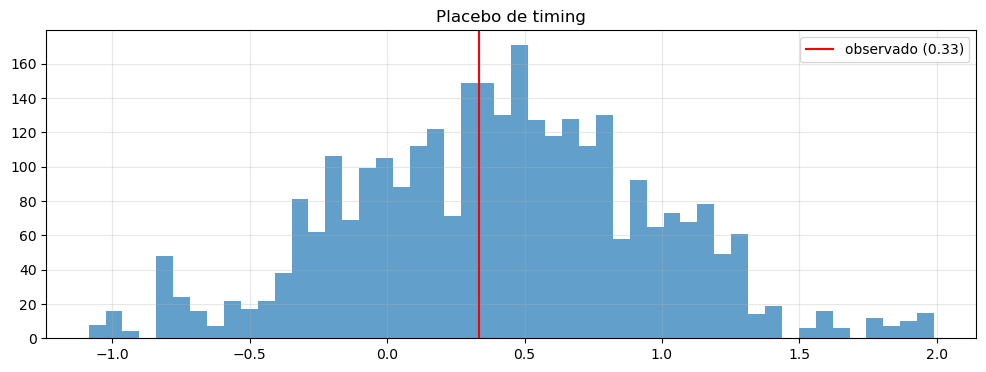

In [14]:
# 3) PLACEBO DE TIMING: desplazamos circularmente la serie de posiciones (mismo nº de operaciones, misma exposición, mismas duraciones)
rv = r_ret.fillna(0).values; pv = pos_model.values; n_ = len(pv)
def sharpe_arr(p):
    pp = np.r_[0, p[:-1]]
    r = pp * rv - COST * np.abs(np.diff(np.r_[0, p]))
    return r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0.0
rng = np.random.default_rng(0)
sims_sh = np.array([sharpe_arr(np.roll(pv, int(rng.integers(20, n_ - 20)))) for _ in range(3000)])
obs = sharpe_arr(pv); p_val = (sims_sh >= obs).mean()
print(f"Sharpe observado = {obs:.2f} | placebo: media {sims_sh.mean():.2f}, p5 {np.percentile(sims_sh, 5):.2f}, p95 {np.percentile(sims_sh, 95):.2f}")
print(f"p-value (prob. de igualar o superar el resultado con fechas al azar) = {p_val:.1%}")
plt.hist(sims_sh, bins=50, alpha=.7); plt.axvline(obs, c="r", label=f"observado ({obs:.2f})"); plt.title("Placebo de timing"); plt.legend(); plt.show()

> ** Cómo leer las tres celdas anteriores — criterio de decisión**
>
> | Prueba | Se considera edge si… |
> |---|---|
> | Operaciones | ≥ 30 operaciones, acierto estable, ninguna operación > ~30 % del PnL |
> | Alfa | alfa > 0 con **t > 2** tras descontar la beta |
> | Placebo | **p-value < 5 %** (el timing importa, no la mera exposición) |
>
> Dado que el backtest mostró ≈ 59 días en mercado, se espera un número muy bajo de operaciones y un p-value del placebo lejos del 5 %. Si el placebo da p ≈ 20–50 %, el resultado equivale a entrar en fechas al azar con la misma exposición: **no es timing, es azar (más algo de deriva alcista)**.

In [15]:
# 4) SENSIBILIDAD (mapa de robustez, NO para elegir el mejor parámetro: sería data snooping)
z_te, p_te_, h_te = z.reindex(idx), pred_full.reindex(idx), hl.reindex(idx)
regime = adf_p.reindex(idx) < 0.10
variants = [("MR puro", z_te, dict(use_model=False)),
            ("MR + NN", z_te, dict(use_model=True)),
            ("MR + filtro ADF", z_te.where(regime), dict(use_model=False)),
            ("MR + NN + filtro ADF", z_te.where(regime), dict(use_model=True)),
            ("MR solo largo", z_te, dict(use_model=False, allow_short=False)),
            ("MR + NN solo largo", z_te, dict(use_model=True, allow_short=False))]
rows = []
for name, zz, kw in variants:
    for ent in (1.0, 1.5, 2.0, 2.5):
        pos = build_positions(zz, p_te_, h_te, entry=ent, **kw)
        r = run_bt(pos, r_ret)
        rows.append(dict(variante=name, entry_z=ent,
                         sharpe=r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan,
                         n_ops=int(((pos != 0) & (pos != pos.shift(1))).sum()), exposicion=(pos != 0).mean()))
sens = pd.DataFrame(rows)
display(sens.pivot(index="variante", columns="entry_z", values="sharpe").round(2))
display(sens.pivot(index="variante", columns="entry_z", values="n_ops"))

entry_z,1.0,1.5,2.0,2.5
variante,,,,
MR + NN,0.21,0.33,0.19,0.01
MR + NN + filtro ADF,-0.78,-0.43,NaN,NaN
MR + NN solo largo,0.21,0.33,0.19,0.01
MR + filtro ADF,-0.43,-0.34,-0.43,NaN
MR puro,-0.42,-0.39,-0.05,-0.24
MR solo largo,0.21,0.33,0.19,0.01


entry_z,1.0,1.5,2.0,2.5
variante,,,,
MR + NN,4,3,2,1
MR + NN + filtro ADF,3,2,0,0
MR + NN solo largo,4,3,2,1
MR + filtro ADF,11,7,2,0
MR puro,16,8,7,3
MR solo largo,4,3,2,1


> **Cómo leer la sensibilidad**
> - Un edge verdadero muestra **Sharpe positivo en la mayoría de las celdas vecinas**, no un solo valor aislado. Un máximo puntual rodeado de ceros/negativos es ruido.
> - Compara *MR puro* vs *solo largo*: si la mejora viene de eliminar el lado corto, confirma que el problema es la deriva alcista, no la idea de reversión.
> - El **filtro ADF** pone a prueba la hipótesis central del proyecto (operar solo en regímenes localmente estacionarios). Si mejora el Sharpe pero reduce las operaciones a un puñado, la conclusión es "prometedor pero sin muestra suficiente".
> - Un umbral más alto (2.0–2.5) suele dar más calidad pero muy pocas operaciones: revisa siempre la segunda tabla.

In [16]:
# 5) EVENT STUDY SOBRE EL PRECIO (lo que realmente se puede operar). Muestra completa, sin modelo.
def event_returns(z, logp, thr=ENTRY_Z, horizons=(1, 5, 10, 20, 40), side="long", min_gap=10):
    cond = ((z < -thr) & (z.shift(1) >= -thr)) if side == "long" else ((z > thr) & (z.shift(1) <= thr))
    where = {d: i for i, d in enumerate(z.index)}
    keep, last = [], -10**9
    for d in z.index[cond.fillna(False).values]:          # eventos separados ≥ min_gap días
        if where[d] - last >= min_gap: keep.append(d); last = where[d]
    rows = []
    for h in horizons:
        fr = (logp.shift(-h) - logp); sel = fr.reindex(keep).dropna(); unc = fr.dropna()
        ex = sel.mean() - unc.mean()
        t = ex / (sel.std() / np.sqrt(len(sel))) if len(sel) > 1 else np.nan
        rows.append(dict(horizonte_d=h, n=len(sel), ret_tras_evento=sel.mean(), ret_incondicional=unc.mean(), exceso=ex, t_stat=t, pct_positivos=(sel > 0).mean()))
    return pd.DataFrame(rows).set_index("horizonte_d")

print(f"Tras caída (z < -{ENTRY_Z}) -> reversión esperada = exceso POSITIVO"); display(event_returns(z, logp, side="long").round(4))
print(f"Tras exceso al alza (z > {ENTRY_Z}) -> reversión esperada = exceso NEGATIVO"); display(event_returns(z, logp, side="short").round(4))

Tras caída (z < -1.5) -> reversión esperada = exceso POSITIVO


,n,ret_tras_evento,ret_incondicional,exceso,t_stat,pct_positivos
horizonte_d,,,,,,
1,31,-0.0020,0.0005,-0.0025,-1.0012,0.5161
5,30,-0.0099,0.0026,-0.0125,-2.0870,0.3667
10,30,0.0033,0.0052,-0.0019,-0.2527,0.5000
20,30,0.0066,0.0105,-0.0039,-0.3096,0.5333
40,30,0.0314,0.0212,0.0102,0.8553,0.7000


Tras exceso al alza (z > 1.5) -> reversión esperada = exceso NEGATIVO


,n,ret_tras_evento,ret_incondicional,exceso,t_stat,pct_positivos
horizonte_d,,,,,,
1,74,-0.0000,0.0005,-0.0006,-0.9583,0.5811
5,74,0.0021,0.0026,-0.0005,-0.3052,0.6622
10,74,0.0024,0.0052,-0.0028,-1.4720,0.6622
20,74,0.0044,0.0105,-0.0061,-1.8094,0.6351
40,74,0.0096,0.0212,-0.0117,-1.8640,0.7162


> ** Cómo leer el event study sobre el precio**
> Es la prueba más honesta de la sección: mide **cuánto sube/baja el *precio*** tras la señal, restando el rendimiento incondicional (la deriva).
> - **Lado largo:** si el exceso a 5–20 días es positivo y |t| > 2, comprar caídas ofrece ventaja real.
> - **Lado corto:** en SPY lo esperable es un exceso *no negativo* (el mercado sigue subiendo tras excesos), lo que confirma que **vender sobrecompra no funciona en un activo con deriva**.
> - Contrasta con el gráfico de decaimiento de la sección 10: si la **desviación** decae en ≈ 23 días pero el **precio** no rinde nada extra, la "reversión" estaba en la media móvil y no en el mercado.

## 10. Decaimiento de la vida media de la anomalía

Estudio de eventos: tomamos cada vez que $z$ **cruza** el umbral de entrada y promediamos cómo decae la anomalía en los días siguientes. Ajustamos

$$\bar z(k) = z_0\,e^{-\lambda k}\quad\Rightarrow\quad t_{1/2}^{emp}=\frac{\ln 2}{\lambda}$$

y lo comparamos con la vida media teórica del OU. Si la anomalía tarda ese tiempo en reducirse a la mitad, **ese es el horizonte máximo razonable para mantener la posición**.

n eventos: 157


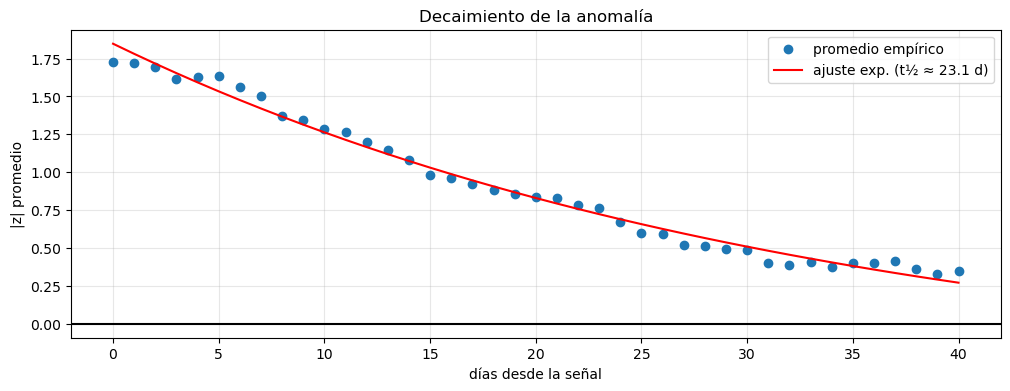

Vida media empírica  : 23.1 días
Vida media OU (mediana móvil): 14.2 días


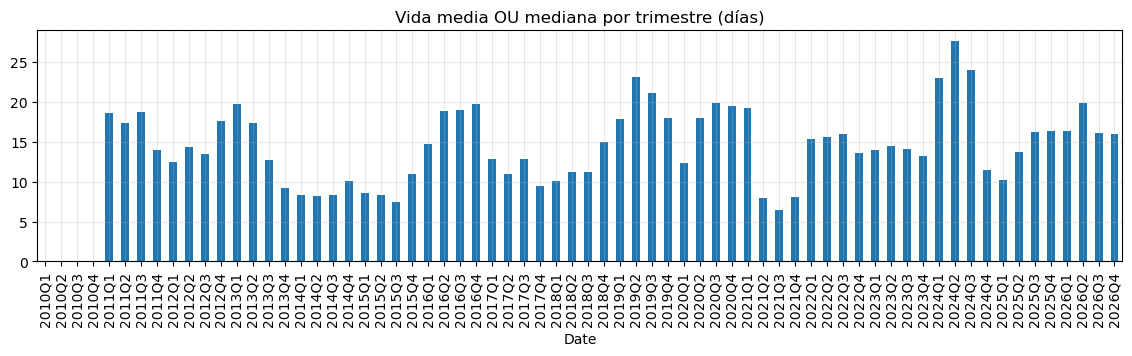

In [17]:
K = 40
zv = z.values; events = []
for t in range(1, len(zv)-K):
    if np.isnan(zv[t]) or np.isnan(zv[t-1]): continue
    if zv[t] < -ENTRY_Z and zv[t-1] >= -ENTRY_Z:   events.append(zv[t:t+K+1])        # anomalía negativa
    elif zv[t] > ENTRY_Z and zv[t-1] <= ENTRY_Z:   events.append(-zv[t:t+K+1])       # simétrica (signo invertido)
ev = np.array(events); print("n eventos:", len(ev))
path = -ev.mean(axis=0)            # magnitud promedio de la desviación (positiva)
ks = np.arange(K+1)
decay = lambda k, z0, lam, c: c + (z0-c)*np.exp(-lam*k)
(popt, _) = curve_fit(decay, ks, path, p0=[path[0], .05, 0], maxfev=10000)
z0, lam, c = popt; hl_emp = np.log(2)/lam
hl_theory = np.nanmedian(hl.reindex(z.index))

plt.plot(ks, path, "o", label="promedio empírico"); plt.plot(ks, decay(ks, *popt), "r-", label=f"ajuste exp. (t½ ≈ {hl_emp:.1f} d)")
plt.axhline(0, c="k"); plt.xlabel("días desde la señal"); plt.ylabel("|z| promedio"); plt.legend(); plt.title("Decaimiento de la anomalía"); plt.show()
print(f"Vida media empírica  : {hl_emp:.1f} días")
print(f"Vida media OU (mediana móvil): {hl_theory:.1f} días")

# ¿La vida media cambia en el tiempo? (decaimiento de la ventaja)
try: hl_q = hl.clip(upper=100).resample("QE").median()
except ValueError: hl_q = hl.clip(upper=100).resample("Q").median()   # pandas < 2.2
hl_q.index = hl_q.index.to_period("Q").astype(str)
hl_q.plot(kind="bar", figsize=(14, 3), title="Vida media OU mediana por trimestre (días)");

> **Lectura de resultados — decaimiento de la vida media (157 eventos)**
> | Medida | Vida media |
> |---|---|
> | Empírica (ajuste exponencial al event study) | **23.1 días** |
> | OU móvil (mediana) | 14.2 días |
> | OU global | 17.3 días |
>
> 1. **La anomalía sí decae:** la desviación promedio pasa de ≈ 1.7σ al entrar a ≈ 0.85σ hacia el día 20–23 y a ≈ 0.35σ al día 40. El ajuste exponencial describe bien el patrón general.
> 2. **No es una exponencial pura:** durante los primeros ≈ 7 días la desviación casi no cambia (≈ 1.7 → 1.5σ) y recién después se acelera; el ajuste (línea roja) sobrestima los primeros días. Operativamente: **la fuerza restauradora tarda en activarse** y entrar y esperar >1 semana sin que pase nada es lo normal, no una señal de fallo.
> 3. **Tres estimaciones, tres números (14 / 17 / 23 días).** La empírica es más lenta que la del OU móvil porque se mide solo en eventos extremos (|z| > 1.5), que coinciden con crisis (2011, 2018, 2020, 2022, 2025) donde la reversión es más lenta que en el régimen normal; es decir, el OU lineal **subestima la persistencia en las colas**.
> 4. **Cuidado con la parte mecánica:** la desviación se mide contra una media de 60 días; incluso si el precio se quedara quieto tras la caída, esa media lo alcanzaría y la desviación llegaría a cero en ≈ 60 días (vida media ≈ 30). El 23.1 observado está solo algo por debajo de ese piso mecánico, lo que indica que la contribución *genuina* del rebote del precio es pequeña. El event study sobre el precio (sección 9b) es el que dice cuánto vale realmente.
> 5. **Uso práctico de la vida media:** como stop temporal (≈ 2 × t½ ≈ 30–45 días) y como estimador de *cuánto dura la ventaja*. La serie trimestral de vida media (gráfico final) permite vigilar si la reversión se debilita; un aumento sostenido es una alerta para reducir tamaño.

## 11. Conclusiones, veredicto y próximos pasos

### Veredicto: ¿constituye un edge?
**No, no con la evidencia actual.** En SPY, fuera de muestra (2023-09 → 2026-11), la estrategia con red neuronal obtiene Sharpe **0.33** (t ≈ 0.6, ≈ 59 días en mercado, pocas operaciones concentradas en 2–3 episodios) frente a **1.24** del buy & hold, y la mean reversion pura pierde (**−0.39**). Esto no refuta la idea; indica que *este diseño, sobre este activo y en este régimen*, no demuestra ventaja estadística. Antes de llamarlo edge deben cumplirse los criterios de la sección 9b (placebo p < 5 %, alfa con t > 2, ≥ 30 operaciones, robustez en la malla de parámetros).

### Lo que sí quedó demostrado
1. **Estacionariedad:** precio y log-precio tienen raíz unitaria; los retornos logarítmicos son estacionarios en media (ADF p ≈ 3·10⁻²⁶), pero la varianza no es constante (clusters de volatilidad). El mercado es dinámico, no un sistema constante.
2. **Estructura tipo OU:** la desviación respecto a su media de 60 días tiene $b=0.961$, $\theta=0.040$ y **vida media ≈ 17 días** (14 días en mediana móvil). Una caminata aleatoria con la misma media móvil daría ≈ 27 días, así que hay algo de reversión por encima del azar (confírmalo con el placebo de la sección 5).
3. **Estacionariedad local, y escasa:** el ADF móvil solo detecta régimen estacionario el **23 %** del tiempo, concentrado en 2014-16 y 2020-22. El periodo de test (2023-26) fue mayormente no estacionario, lo que explica la baja exposición y los malos resultados.
4. **Decaimiento de la anomalía:** la desviación tarda ≈ **23 días** en reducirse a la mitad, con una fase inicial lenta de ≈ 7 días.

### Por qué no apareció el edge (hipótesis respaldadas por los datos)
- **Deriva alcista:** $\mu=+1.5\%$ ≠ 0. El "centro de gravedad" no es fijo y vender sobrecompra pelea contra la tendencia (lado corto perdedor).
- **Asimetría:** las caídas son profundas y raras; los excesos al alza, superficiales y persistentes. La reversión es una propiedad del *lado largo en pánicos*, justo donde el OU lineal falla más (abril-2025: z < −1.5 y el precio siguió cayendo).
- **Reversión parcialmente mecánica:** medir contra una media móvil crea autocorrelación artificial y una vida media inflada.
- **Cambio de régimen train→test:** el modelo aprendió en un periodo con muchas ventanas estacionarias y se evaluó en otro con pocas.
- **Poca muestra:** un solo activo con ~59 días de exposición no permite distinguir habilidad de suerte.
- **La red es un filtro, no un generador de alfa:** su mayor aporte fue operar menos (45 % → 7.5 % del tiempo). Su IC (0.134) es marginal una vez corregido el solapamiento de ventanas, y su acierto (61 %) debe compararse con la tasa base alcista.

### Qué hacer para buscar un edge real (en orden de prioridad)
1. **Pares/spreads cointegrados** (KO–PEP, XLE–XOM, GLD–GDX…): el spread *sí* es estacionario por construcción y neutraliza la deriva y gran parte de la beta. Es donde el OU tiene fundamento económico.
2. **Muchos activos en lugar de uno:** una cesta de 30–100 activos o pares da cientos de operaciones independientes y permite una prueba estadística válida.
3. **Centrar la desviación** (restar $\mu$ local o usar retornos residuales) y/o operar **solo el lado largo** con filtro de régimen (ADF/vida media < 30 días).
4. **Filtro de crisis:** no comprar caídas cuando la volatilidad o el VIX estén en máximos y el ADF p > 0.5 (la reversión se rompe en los pánicos).
5. **Validación walk-forward con reentrenamiento periódico**, costos realistas (spread, slippage) y *deflated Sharpe ratio* si pruebas muchas variantes.
6. **Gestión del tiempo:** salida por vida media (≈ 2 × t½) y tamaño de posición decreciente a medida que la vida media rolling se alarga.

### Cómo usar la vida media en la práctica
La vida media dice **cuánto esperar**, no si habrá reversión: con t½ ≈ 15–25 días, una posición debería mantenerse del orden de 1–2 vidas medias (~3–6 semanas). Si tras 2 × t½ la desviación no se redujo, la ventaja se agotó y conviene salir. Vigila su evolución en el tiempo: una vida media que crece de forma sostenida o un p-value ADF que se dispara indican que el régimen dejó de ser localmente estacionario.

> ¡NOTA! Material educativo, no es asesoría financiera. Los resultados pasados (incluso fuera de muestra) no garantizan resultados futuros.